# Delivery Time Estimation: Models, Tuning and Evaluation

**Notebook 3 of the project.** Run the cells one by one from top to bottom (Shift + Enter). The whole notebook takes about 5 to 10 minutes; the tuning step is the slow one.

<br>

## What this notebook does

| Item | Detail |
|---|---|
| Input | `data/processed/features_data.csv` (made by notebook 2: 15 features + target, 41,863 orders) |
| Output | `models/model.pkl` (the best model, with all preprocessing inside) |
| | `models/model_report.json` (scores, error range and settings the app needs) |

<br>

## Where this sits in the pipeline

```
Notebook 1: Load -> Quality audit -> Clean -> EDA
Notebook 2: Feature engineering -> Feature selection
Notebook 3: Split -> Pipeline -> 4 models -> Tune -> Cross validate -> Test -> Explain -> Save   <- you are here
App:        Streamlit UI (uses model.pkl)
```

<br>

## Plan

1. Split the data into training (80%) and test (20%) sets
2. Build one preprocessing pipeline (fill missing values, scale numbers, one-hot encode categories)
3. Train 4 models with default settings and compare them with 5-fold cross validation
4. Check that our new features really help
5. Tune the models with RandomizedSearchCV
6. Pick the best model, then test it once on the hidden test set
7. Study the errors, explain the model, and build a prediction range
8. Save the model and a report for the app

## Step 0: Setup

In [1]:
# os for folders, json for saving the report, time for measuring how long steps take
import os
import json
import time

# hide routine library warnings so the output stays readable
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# joblib saves and loads trained models
import joblib

# scikit-learn: data splitting, preprocessing, models, tuning, metrics
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# XGBoost: a fast gradient boosting library
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
COLOR = "#3B6EA5"

# one fixed random seed everywhere, so every run gives the same results
SEED = 42

In [2]:
# On your laptop the file is in data/processed/ (made by notebook 2)
DATA_PATH = "data/processed/features_data.csv"

# In Google Colab: upload features_data.csv with the folder icon on the left
if not os.path.exists(DATA_PATH):
    DATA_PATH = "features_data.csv"

df = pd.read_csv(DATA_PATH)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 41863 | Columns: 16


,distance_km,multiple_deliveries,rider_rating,is_high_rated,rider_age,is_age_30_plus,vehicle_condition,order_hour,is_peak_hour,weather,traffic,city_type,festival,vehicle_type,order_type,delivery_time_min
0,10.280582,3.0,4.2,0.0,36.0,1.0,2,21.0,1.0,Fog,Jam,Metropolitan,No,motorcycle,Snack,46
1,6.242319,1.0,4.7,1.0,21.0,0.0,1,14.0,0.0,Stormy,High,Metropolitan,No,motorcycle,Meal,23
2,13.787860,1.0,4.7,1.0,23.0,0.0,1,17.0,0.0,Sandstorms,Medium,Metropolitan,No,scooter,Drinks,21
3,2.930258,0.0,4.3,0.0,34.0,1.0,0,9.0,0.0,Sandstorms,Low,Metropolitan,No,motorcycle,Buffet,20
4,19.396618,1.0,4.7,1.0,24.0,0.0,1,19.0,1.0,Fog,Jam,Metropolitan,No,scooter,Snack,41


## Step 1: Inputs (X) and target (y)

In [3]:
TARGET = "delivery_time_min"

NUMERIC_FEATURES = ["distance_km", "multiple_deliveries", "rider_rating", "is_high_rated",
                    "rider_age", "is_age_30_plus", "vehicle_condition", "order_hour", "is_peak_hour"]

CATEGORICAL_FEATURES = ["weather", "traffic", "city_type", "festival", "vehicle_type", "order_type"]

# X = what the model sees, y = what it must predict
X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = df[TARGET]

print("X:", X.shape, "| y:", y.shape)

X: (41863, 15) | y: (41863,)


## Step 2: Split into training and test sets

We split **before** doing anything else. The test set (20%) is locked away and used only once, at the very end. It plays the role of "new orders the model has never seen". Everything else (training, cross validation, tuning) uses only the training set (80%).

In [4]:
# test_size=0.2 -> 20% test, 80% training; random_state fixes the shuffle so it's repeatable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

print("Training rows:", len(X_train))
print("Test rows:    ", len(X_test))
print("Average delivery time - train:", round(y_train.mean(), 2), "| test:", round(y_test.mean(), 2))

Training rows: 33490
Test rows:     8373
Average delivery time - train: 26.32 | test: 26.29


## Step 3: The preprocessing pipeline

Models need complete, numeric input. The pipeline does three jobs:

| Column type | Step 1 | Step 2 |
|---|---|---|
| Numeric | Fill missing values with the **median** | **Scale** so every column has mean 0 and std 1 (needed by Linear Regression and the ANN) |
| Categorical | Fill missing values with the **most frequent** value | **One-hot encode**: one 0/1 column per category (e.g. weather_Fog) |

These steps are joined to the model in one `Pipeline`. During cross validation the pipeline learns the median, scaling and categories **only from the training part of each fold**, so no information leaks from the data it is tested on.

In [5]:
# numeric columns: fill gaps with the median, then scale
numeric_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# categorical columns: fill gaps with the most common value, then one-hot encode
# handle_unknown="ignore" means a category never seen in training will not crash the model
categorical_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

# ColumnTransformer sends each group of columns to its own steps
preprocessor = ColumnTransformer([
    ("num", numeric_steps, NUMERIC_FEATURES),
    ("cat", categorical_steps, CATEGORICAL_FEATURES),
])

# quick look: 15 input columns become this many columns after one-hot encoding
print("Columns after preprocessing:", preprocessor.fit_transform(X_train).shape[1])

Columns after preprocessing: 32


## Step 4: The four models

| Model | How it works, in one line |
|---|---|
| **Linear Regression** | Fits a straight-line formula: time = a×distance + b×traffic + ... Our baseline, as the problem statement asks. |
| **Random Forest** | Builds many decision trees on random parts of the data and averages their answers. |
| **XGBoost** | Builds trees one after another; each new tree corrects the mistakes of the trees before it. |
| **ANN (MLPRegressor)** | A neural network: input layer, two hidden layers of 64 and 32 neurons (ReLU activation), and one output neuron. Trained with the Adam optimiser, with early stopping to avoid overfitting. |

Each model is wrapped together with the preprocessor into one pipeline by a small helper, `build_pipeline`.

In [6]:
def build_pipeline(model):
    # preprocessing first, then the model
    # clone() makes a fresh, untrained copy, so no two pipelines share the same parts
    return Pipeline([("pre", clone(preprocessor)), ("model", clone(model))])


base_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=SEED, n_jobs=-1),
    "ANN (MLP)": MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=300, random_state=SEED),
}

## Step 5: Compare the models with 5-fold cross validation

**5-fold cross validation:** the training set is cut into 5 parts. The model trains on 4 parts and is scored on the 5th, and this repeats 5 times so every part is scored once. We report the average and the spread (std) over the 5 rounds. That's much more reliable than a single score.

**Metrics:**
- **MAE** (mean absolute error): on average, how many minutes we are off. Lower is better. Our main metric.
- **RMSE** (root mean squared error): like MAE, but punishes big misses more. Lower is better.
- **R²**: the share of the variation in delivery time the model explains (1.0 = perfect). Higher is better.

In [7]:
# the same 5 folds for every model, so the comparison is fair
kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)

# scikit-learn reports errors as negative numbers (so that "higher is better" everywhere)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}


def cross_validate_model(pipeline):
    # train and score the pipeline 5 times, return the average scores
    result = cross_validate(pipeline, X_train, y_train, cv=kfold, scoring=scoring)
    return {
        "MAE": -result["test_MAE"].mean(),
        "MAE_std": result["test_MAE"].std(),
        "RMSE": -result["test_RMSE"].mean(),
        "R2": result["test_R2"].mean(),
    }


baseline_scores = {}
for name, model in base_models.items():
    start = time.time()
    baseline_scores[name] = cross_validate_model(build_pipeline(model))
    print(f"{name:18s} done in {time.time() - start:.0f} s")

baseline_table = pd.DataFrame(baseline_scores).T.round(3)
baseline_table

Linear Regression  done in 1 s


Random Forest      done in 54 s


XGBoost            done in 3 s


ANN (MLP)          done in 34 s


,MAE,MAE_std,RMSE,R2
Linear Regression,4.580,0.051,5.786,0.618
Random Forest,3.202,0.022,4.046,0.813
XGBoost,3.153,0.022,3.975,0.820
ANN (MLP),3.206,0.023,4.040,0.814


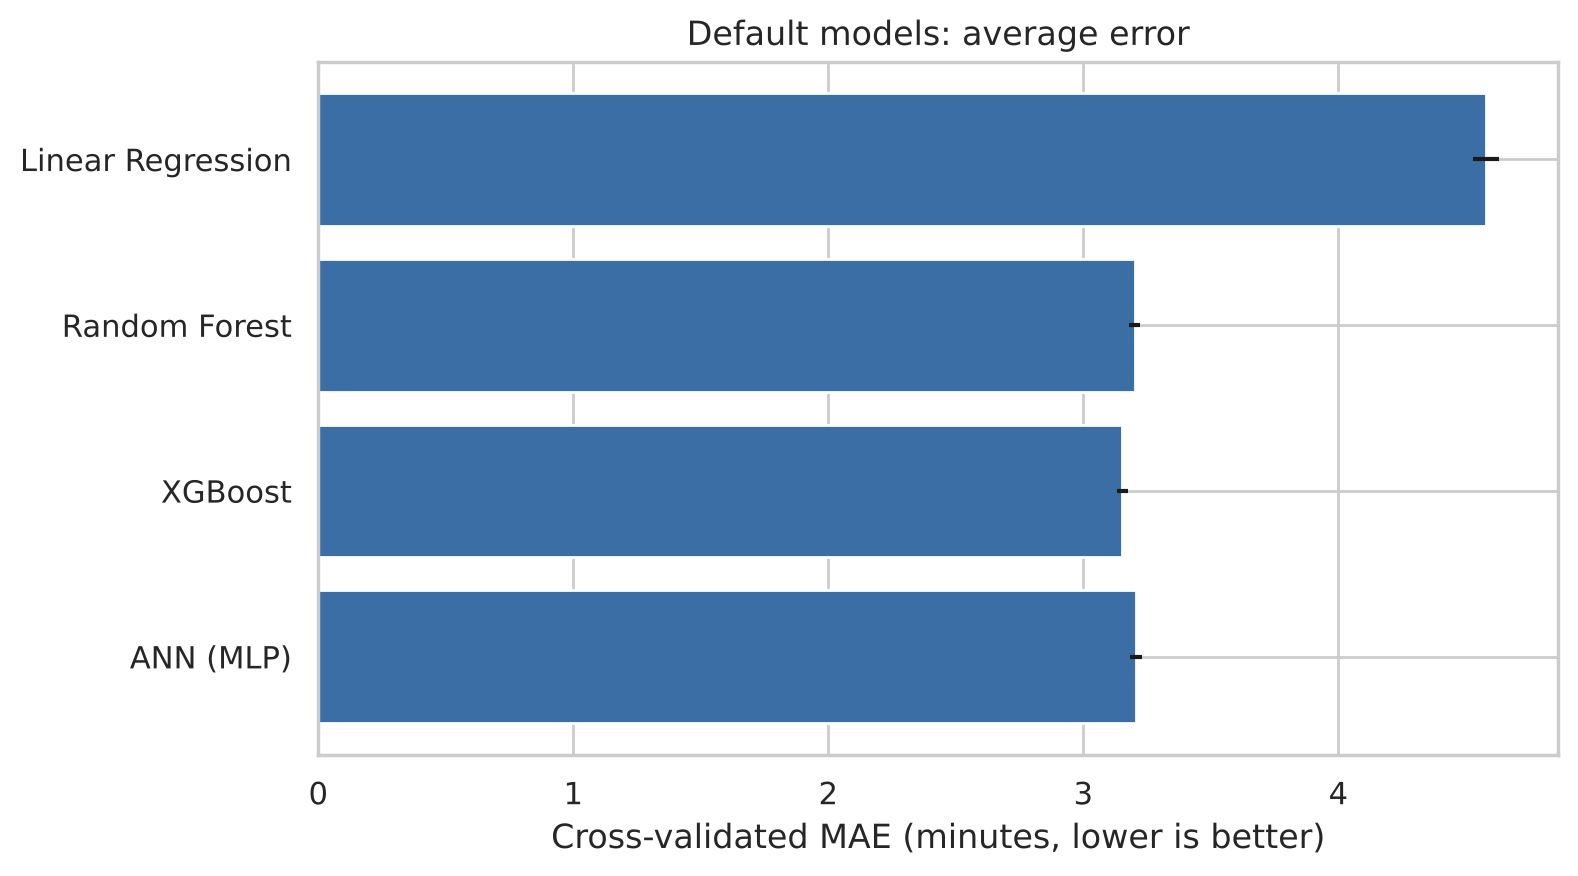

In [8]:
plt.figure(figsize=(8, 4.5))
plt.barh(baseline_table.index, baseline_table["MAE"], xerr=baseline_table["MAE_std"], color=COLOR)
plt.gca().invert_yaxis()
plt.xlabel("Cross-validated MAE (minutes, lower is better)")
plt.title("Default models: average error")
plt.show()

**What we see (default settings):** Linear Regression is off by 4.58 min on average (R² 0.62). The three non-linear models are all close to 3.2 min (R² about 0.81 to 0.82), and XGBoost is the best at 3.15. The ± spread across folds is tiny (about 0.02), so these scores are stable.

This matches what EDA predicted: the strongest patterns are steps and curves, and a straight line can't follow them.

## Step 6: Do our new features really help?

We repeat the cross validation for Linear Regression and XGBoost **without** the 5 features from notebook 2 (distance_km, order_hour, is_peak_hour, is_high_rated, is_age_30_plus), and compare.

In [9]:
NEW_FEATURES = ["distance_km", "order_hour", "is_peak_hour", "is_high_rated", "is_age_30_plus"]
OLD_NUMERIC = [col for col in NUMERIC_FEATURES if col not in NEW_FEATURES]

# a preprocessor that only knows the original columns
preprocessor_without_new = ColumnTransformer([
    ("num", numeric_steps, OLD_NUMERIC),
    ("cat", categorical_steps, CATEGORICAL_FEATURES),
])

feature_check = {}
for name in ["Linear Regression", "XGBoost"]:
    pipeline_without_new = Pipeline([("pre", preprocessor_without_new), ("model", base_models[name])])
    result = cross_validate(pipeline_without_new, X_train[OLD_NUMERIC + CATEGORICAL_FEATURES], y_train,
                            cv=kfold, scoring="neg_mean_absolute_error")
    mae_without = -result["test_score"].mean()
    mae_with = baseline_scores[name]["MAE"]
    feature_check[name] = {"MAE without new features": mae_without,
                           "MAE with new features": mae_with,
                           "Improvement (%)": (mae_without - mae_with) / mae_without * 100}

pd.DataFrame(feature_check).T.round(2)

,MAE without new features,MAE with new features,Improvement (%)
Linear Regression,4.95,4.58,7.54
XGBoost,3.95,3.15,20.28


**What we see:** the new features cut XGBoost's error from 3.95 to 3.15 min (about 20% better) and Linear Regression's from 4.95 to 4.58 min. Feature engineering gave a bigger gain than any tuning will.

## Step 7: Hyperparameter tuning (RandomizedSearchCV)

Every model has settings (hyperparameters) we choose before training, like the number of trees or the learning rate. **RandomizedSearchCV** tries a set number of random combinations from a list we give it and keeps the one with the lowest cross-validated error.

- We use 3-fold cross validation inside the search to keep it fast.
- Linear Regression has nothing to tune, so it is skipped.
- Model settings are written as `model__<setting>` because the model sits inside the pipeline under the name "model".

In [10]:
search_spaces = {
    "XGBoost": {
        "model__n_estimators": [300, 500, 700, 900],     # number of trees
        "model__learning_rate": [0.03, 0.05, 0.1],       # how big a step each tree takes
        "model__max_depth": [4, 6, 8],                   # how deep each tree can grow
        "model__subsample": [0.7, 0.85, 1.0],            # share of rows each tree sees
        "model__colsample_bytree": [0.6, 0.8, 1.0],      # share of columns each tree sees
        "model__min_child_weight": [1, 3, 5],            # minimum data needed to make a split
    },
    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 15, 20, 25],
        "model__min_samples_leaf": [1, 2, 4, 8],         # minimum orders in each leaf
        "model__max_features": [0.5, 0.7, 1.0],          # share of columns tried at each split
    },
    "ANN (MLP)": {
        "model__hidden_layer_sizes": [(64, 32), (128, 64), (128, 64, 32), (64, 64, 32)],
        "model__alpha": [0.0001, 0.001, 0.01],           # regularisation strength
        "model__learning_rate_init": [0.001, 0.003, 0.01],
    },
}

# how many random combinations to try for each model
search_iterations = {"XGBoost": 20, "Random Forest": 8, "ANN (MLP)": 8}

# fresh, untuned copies of each model to start the search from
search_models = {
    "XGBoost": XGBRegressor(random_state=SEED, n_jobs=-1),
    "Random Forest": RandomForestRegressor(random_state=SEED, n_jobs=-1),
    "ANN (MLP)": MLPRegressor(early_stopping=True, max_iter=300, random_state=SEED),
}

In [11]:
three_fold = KFold(n_splits=3, shuffle=True, random_state=SEED)
best_settings = {}
tuned_pipelines = {}

for name in search_spaces:
    start = time.time()
    search = RandomizedSearchCV(
        build_pipeline(search_models[name]),
        param_distributions=search_spaces[name],
        n_iter=search_iterations[name],
        cv=three_fold,
        scoring="neg_mean_absolute_error",
        random_state=SEED,
    )
    search.fit(X_train, y_train)

    tuned_pipelines[name] = search.best_estimator_
    best_settings[name] = search.best_params_
    print(f"{name:14s} best 3-fold MAE {-search.best_score_:.3f}  ({time.time() - start:.0f} s)")
    print("               best settings:", search.best_params_, "\n")

XGBoost        best 3-fold MAE 3.121  (73 s)
               best settings: {'model__subsample': 0.7, 'model__n_estimators': 300, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0} 



Random Forest  best 3-fold MAE 3.146  (126 s)
               best settings: {'model__n_estimators': 100, 'model__min_samples_leaf': 8, 'model__max_features': 0.5, 'model__max_depth': 25} 



ANN (MLP)      best 3-fold MAE 3.217  (126 s)
               best settings: {'model__learning_rate_init': 0.003, 'model__hidden_layer_sizes': (128, 64, 32), 'model__alpha': 0.01} 



### Tuned vs default, on the same 5 folds

To compare fairly, we score every tuned model with the same 5-fold cross validation as in step 5. For each model we keep whichever version (default or tuned) has the lower error.

In [12]:
final_pipelines = {"Linear Regression": build_pipeline(base_models["Linear Regression"])}
comparison_rows = []

for name in ["Random Forest", "XGBoost", "ANN (MLP)"]:
    tuned_scores = cross_validate_model(tuned_pipelines[name])
    default_mae = baseline_scores[name]["MAE"]

    # keep the tuned version only if it is actually better
    if tuned_scores["MAE"] < default_mae:
        final_pipelines[name] = tuned_pipelines[name]
        kept = "tuned"
    else:
        final_pipelines[name] = build_pipeline(base_models[name])
        kept = "default"

    comparison_rows.append({"model": name, "default MAE": default_mae,
                            "tuned MAE": tuned_scores["MAE"], "tuned R2": tuned_scores["R2"], "kept": kept})

tuning_table = pd.DataFrame(comparison_rows).set_index("model").round(3)
tuning_table

,default MAE,tuned MAE,tuned R2,kept
model,,,,
Random Forest,3.202,3.132,0.823,tuned
XGBoost,3.153,3.106,0.826,tuned
ANN (MLP),3.206,3.215,0.813,default


**What we see:** tuning lowers XGBoost's error from 3.153 to 3.106 min and Random Forest's from 3.202 to 3.132 min. The ANN did not improve (3.206 default vs 3.215 tuned), so we keep its default version. Being honest about this matters: tuning is a search, and sometimes the default is already good.

In [13]:
# final cross-validated score for each model (the version we kept)
final_cv = {}
for name in ["Linear Regression", "Random Forest", "XGBoost", "ANN (MLP)"]:
    if name == "Linear Regression":
        final_cv[name] = baseline_scores[name]
    elif tuning_table.loc[name, "kept"] == "tuned":
        final_cv[name] = {"MAE": tuning_table.loc[name, "tuned MAE"], "R2": tuning_table.loc[name, "tuned R2"]}
    else:
        final_cv[name] = baseline_scores[name]

final_cv_table = pd.DataFrame(final_cv).T[["MAE", "R2"]].astype(float).round(3).sort_values("MAE")

# the best model = lowest cross-validated MAE
BEST_MODEL_NAME = final_cv_table.index[0]
print("Best model by cross validation:", BEST_MODEL_NAME)
final_cv_table

Best model by cross validation: XGBoost


,MAE,R2
XGBoost,3.106,0.826
Random Forest,3.132,0.823
ANN (MLP),3.206,0.814
Linear Regression,4.580,0.618


## Step 8: Final test on the hidden test set

Now, and only now, we use the test set. Each final model trains on the full training set and predicts the 8,373 test orders it has never seen.

We also add a **naive baseline**: always predict the average delivery time from the training set. Any useful model must beat it by a wide margin.

In [14]:
test_rows = []

# naive baseline: predict the training average for every order
naive_prediction = np.full(len(y_test), y_train.mean())
test_rows.append({"model": "Naive (always the average)",
                  "MAE": mean_absolute_error(y_test, naive_prediction),
                  "RMSE": np.sqrt(mean_squared_error(y_test, naive_prediction)),
                  "R2": r2_score(y_test, naive_prediction)})

for name, pipeline in final_pipelines.items():
    pipeline.fit(X_train, y_train)          # train on all training data
    prediction = pipeline.predict(X_test)   # predict orders it has never seen
    test_rows.append({"model": name,
                      "MAE": mean_absolute_error(y_test, prediction),
                      "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
                      "R2": r2_score(y_test, prediction)})

test_table = pd.DataFrame(test_rows).set_index("model").round(3)
test_table

,MAE,RMSE,R2
model,,,
Naive (always the average),7.656,9.461,-0.000
Linear Regression,4.603,5.817,0.622
Random Forest,3.089,3.863,0.833
XGBoost,3.074,3.857,0.834
ANN (MLP),3.167,3.975,0.824


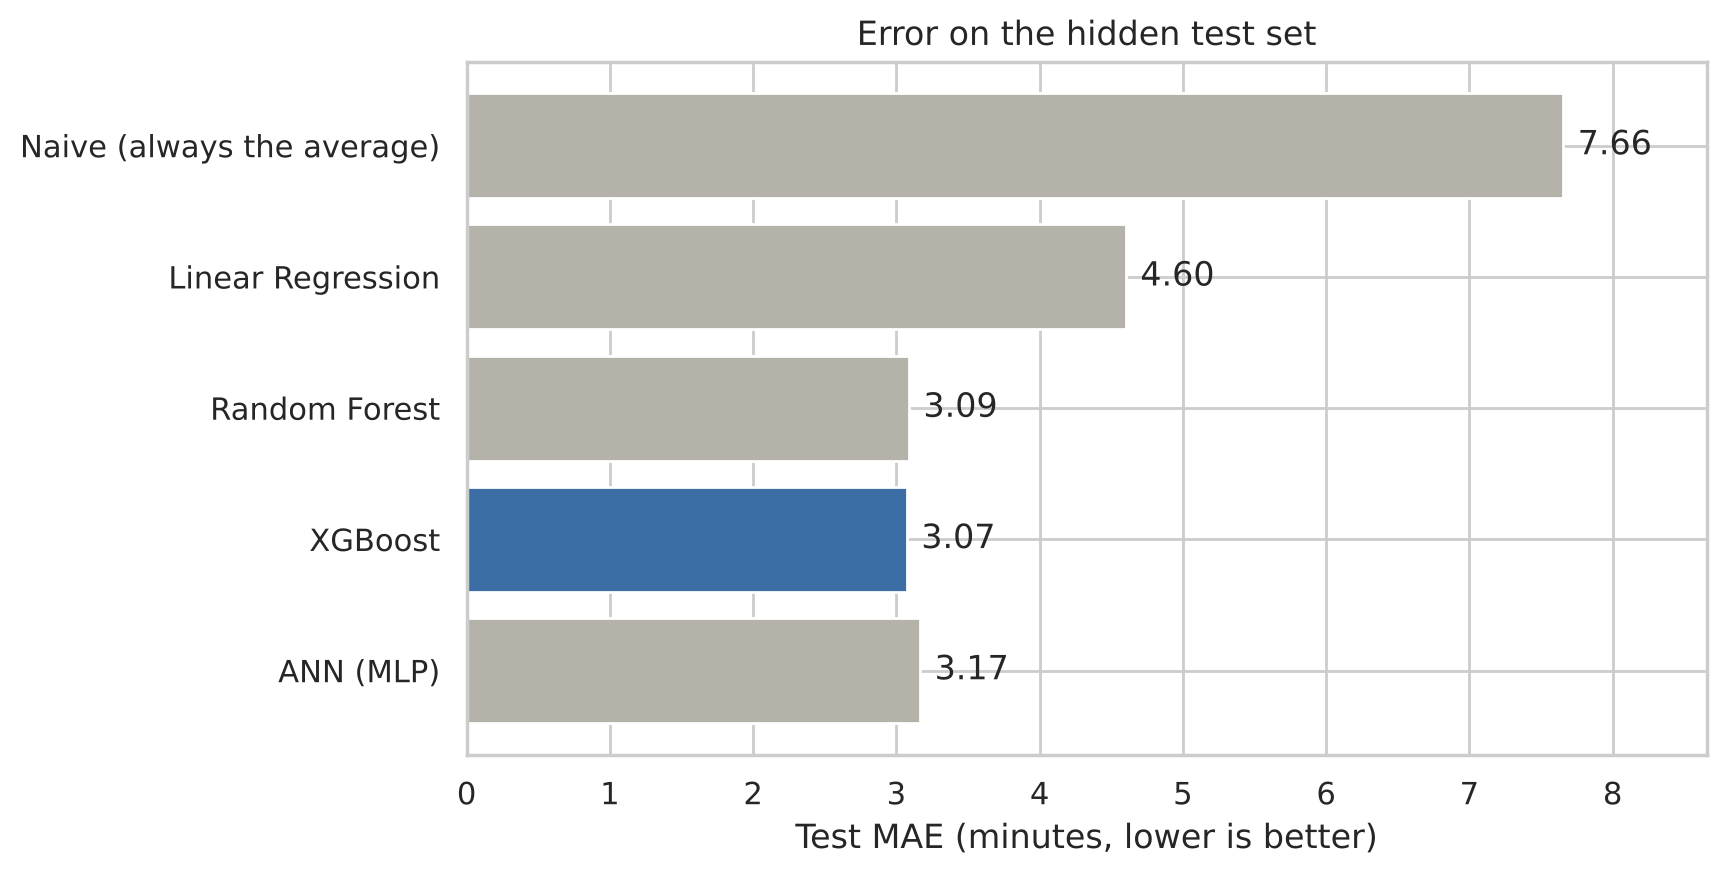

In [15]:
plt.figure(figsize=(8, 4.5))
colors = ["#B4B2A9" if name != BEST_MODEL_NAME else COLOR for name in test_table.index]
plt.barh(test_table.index, test_table["MAE"], color=colors)
plt.gca().invert_yaxis()
for position, value in enumerate(test_table["MAE"]):
    plt.text(value + 0.1, position, f"{value:.2f}", va="center")
plt.xlabel("Test MAE (minutes, lower is better)")
plt.title("Error on the hidden test set")
plt.xlim(0, test_table["MAE"].max() + 1)
plt.show()

**What we see:**
- **XGBoost wins: MAE 3.07 min, RMSE 3.86 min, R² 0.83** on orders it never saw.
- Random Forest is a very close second (3.09), the ANN is third (3.17), and Linear Regression is far behind (4.60).
- The naive baseline is off by 7.66 min, so our model **cuts the error by 60%**.
- The test scores are as good as the cross-validated ones, so the model is not overfitting.

## Step 9: Error analysis of the best model

A single MAE number hides a lot. Here we ask: how often is the model close, and where does it struggle?

In [16]:
best_pipeline = final_pipelines[BEST_MODEL_NAME]
best_prediction = best_pipeline.predict(X_test)

# error = actual - predicted (positive means the delivery took longer than predicted)
errors = y_test - best_prediction

print(f"Predictions within 3 minutes:  {(errors.abs() <= 3).mean() * 100:.1f}%")
print(f"Predictions within 5 minutes:  {(errors.abs() <= 5).mean() * 100:.1f}%")
print(f"Predictions within 10 minutes: {(errors.abs() <= 10).mean() * 100:.1f}%")

Predictions within 3 minutes:  55.6%
Predictions within 5 minutes:  81.6%
Predictions within 10 minutes: 98.9%


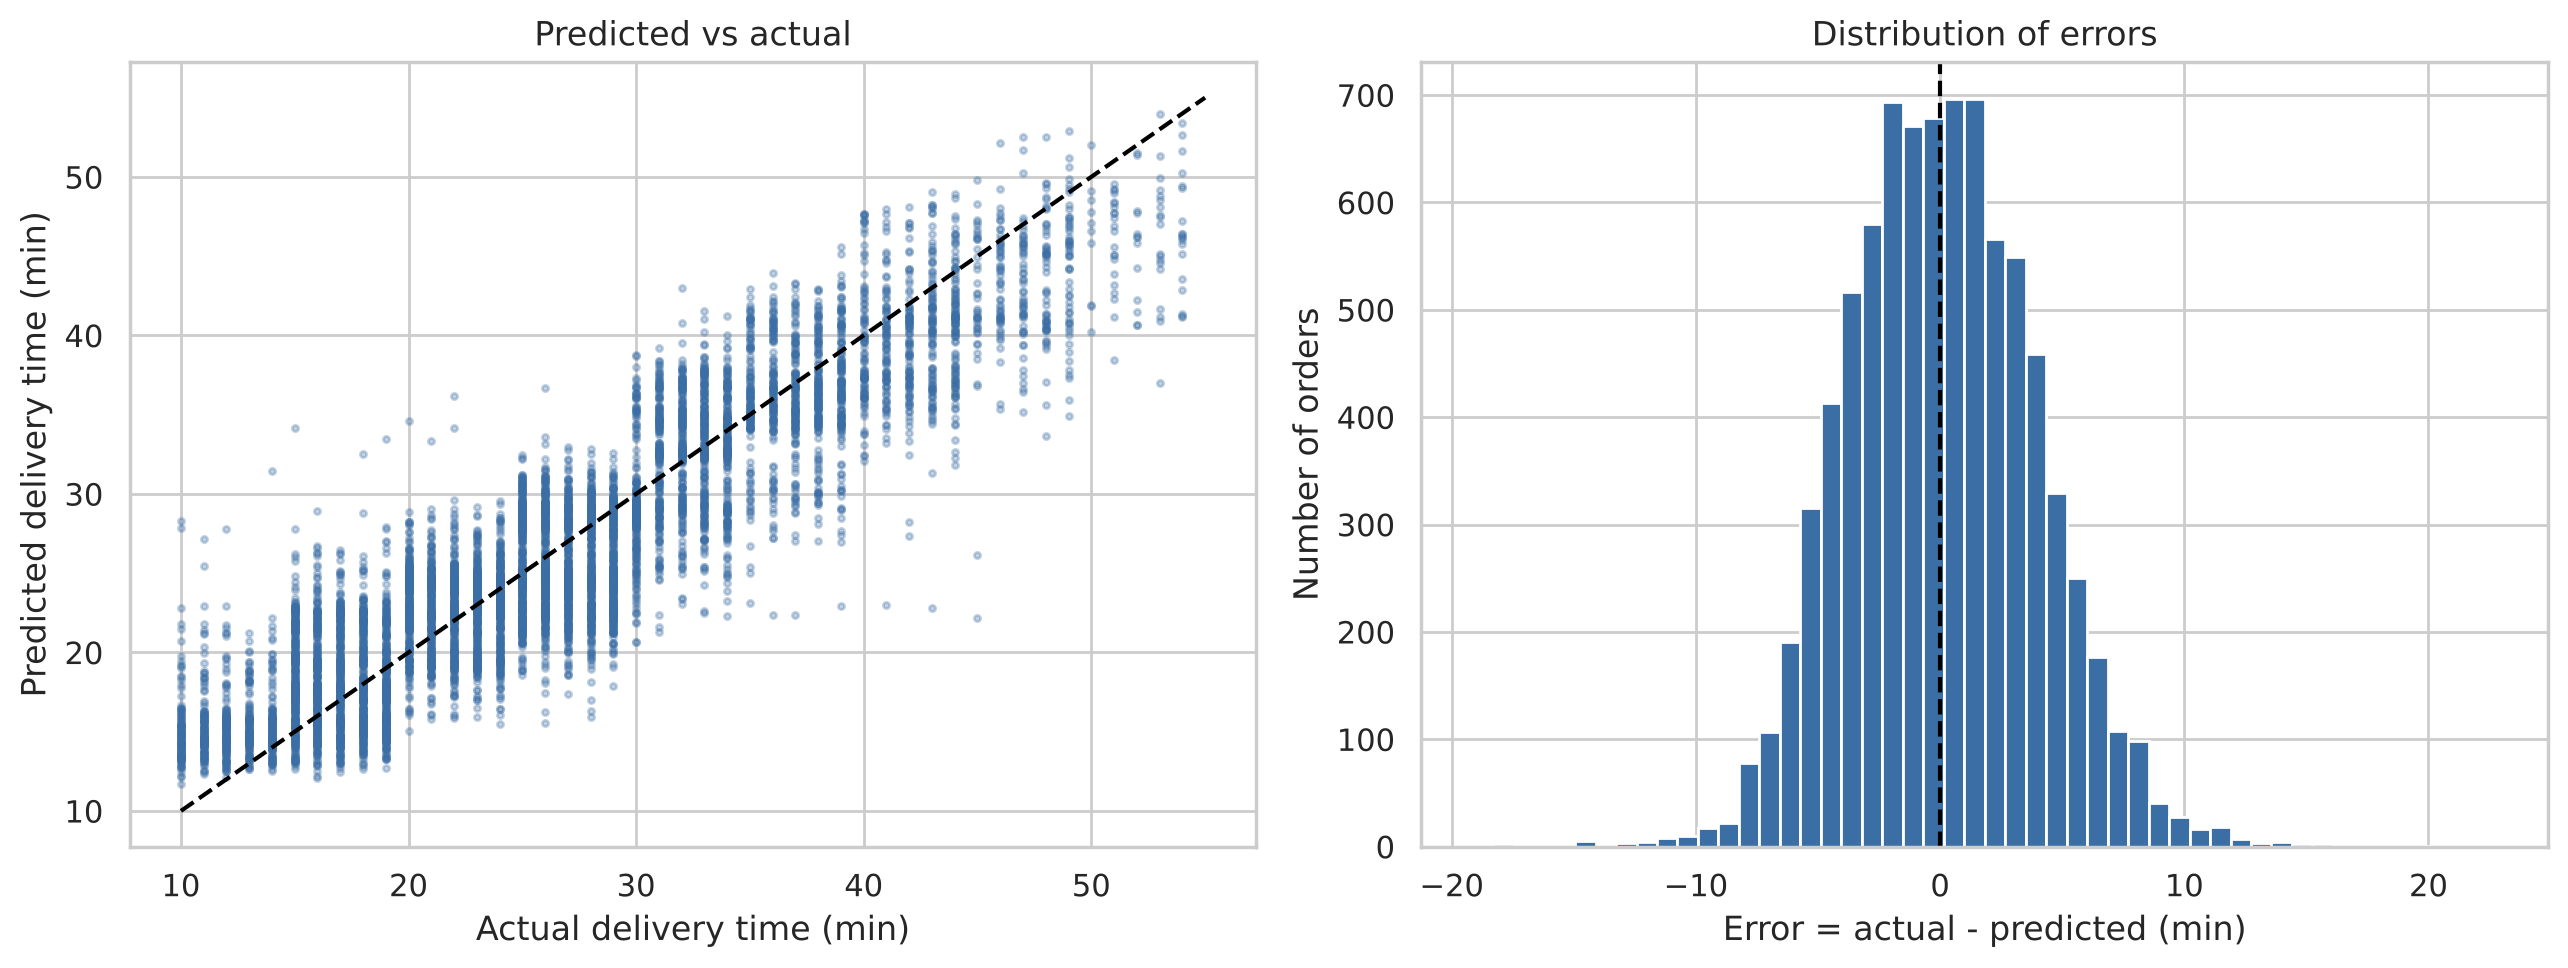

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# left: predicted vs actual (perfect predictions would sit on the dashed line)
axes[0].scatter(y_test, best_prediction, s=5, alpha=0.3, color=COLOR)
axes[0].plot([10, 55], [10, 55], color="black", linestyle="--")
axes[0].set_xlabel("Actual delivery time (min)")
axes[0].set_ylabel("Predicted delivery time (min)")
axes[0].set_title("Predicted vs actual")

# right: how the errors are spread
axes[1].hist(errors, bins=50, color=COLOR, edgecolor="white")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_xlabel("Error = actual - predicted (min)")
axes[1].set_ylabel("Number of orders")
axes[1].set_title("Distribution of errors")

plt.tight_layout()
plt.show()

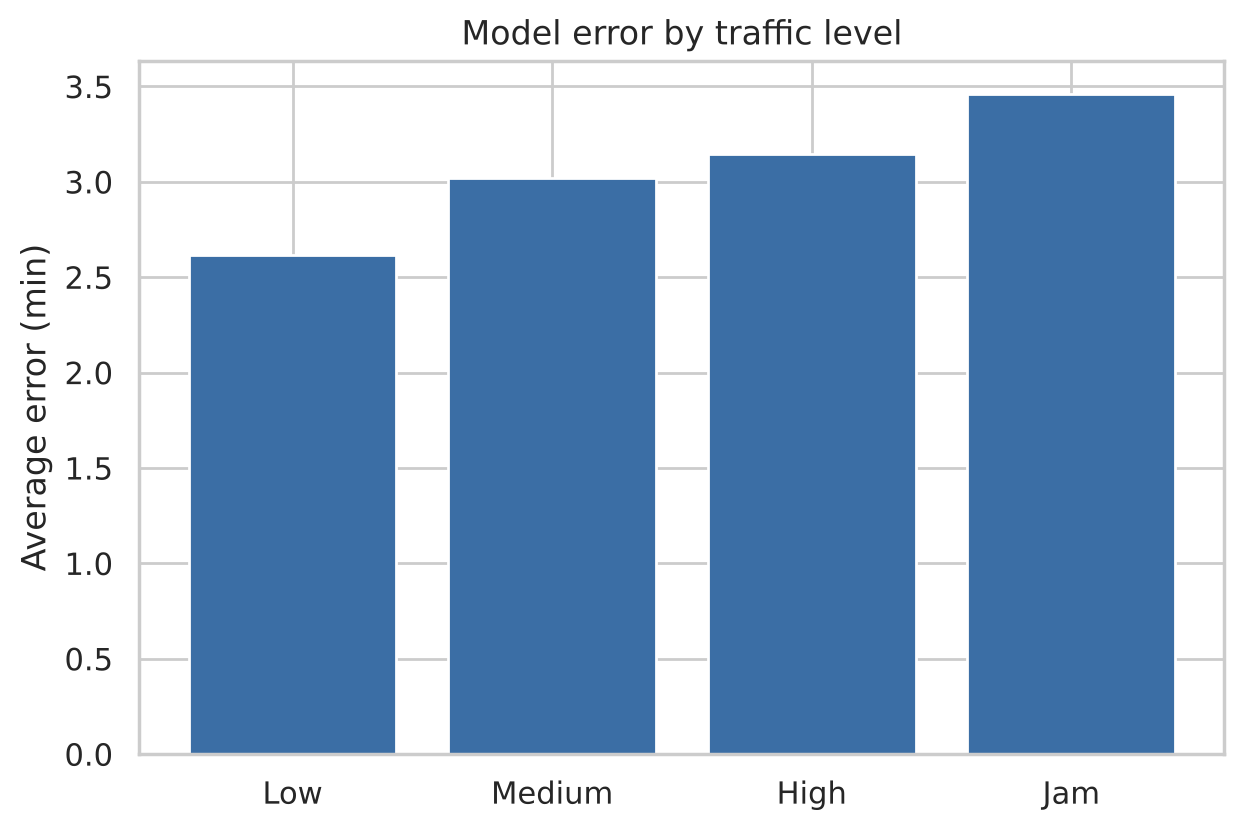

traffic
Low       2.61
Medium    3.02
High      3.15
Jam       3.46
Name: abs_error, dtype: float64

In [18]:
# average error for each traffic level: where does the model struggle?
error_table = X_test[["traffic"]].copy()
error_table["abs_error"] = errors.abs()
traffic_error = error_table.groupby("traffic")["abs_error"].mean().reindex(["Low", "Medium", "High", "Jam"])

plt.figure(figsize=(7, 4.5))
plt.bar(traffic_error.index, traffic_error.values, color=COLOR)
plt.ylabel("Average error (min)")
plt.title("Model error by traffic level")
plt.show()

traffic_error.round(2)

**What we see:**
- 55.6% of predictions are within 3 minutes, 81.6% within 5 minutes, and 98.9% within 10 minutes.
- The points follow the diagonal, and the errors are centred on 0, so the model is not biased up or down.
- The model is most accurate in low traffic (2.6 min) and least accurate in a jam (3.5 min). Jams are less predictable, which makes sense.

## Step 10: Prediction range (instead of a single number)

Real delivery apps show a range like "28 to 34 min". We build one from the model's own errors:

1. Use 5-fold cross validation to get an honest prediction for every **training** order (`cross_val_predict`).
2. Look at the errors: the 10th and 90th percentiles give a band that holds 80% of the errors.
3. Range for a new order = prediction + lower limit to prediction + upper limit.
4. Check on the **test** set that about 80% of real times fall inside the range.

In [19]:
# honest predictions for the training set (each order is predicted by a model that did not train on it)
cv_prediction = cross_val_predict(best_pipeline, X_train, y_train, cv=kfold)
cv_errors = y_train - cv_prediction

RANGE_LOW = np.percentile(cv_errors, 10)    # 10% of errors are below this
RANGE_HIGH = np.percentile(cv_errors, 90)   # 10% of errors are above this
print(f"Range: prediction {RANGE_LOW:+.1f} min to prediction {RANGE_HIGH:+.1f} min")

# check on the test set: how often does the real time land inside the range?
inside = (y_test >= best_prediction + RANGE_LOW) & (y_test <= best_prediction + RANGE_HIGH)
print(f"Share of test orders inside the range: {inside.mean() * 100:.1f}% (target 80%)")

Range: prediction -4.7 min to prediction +5.0 min
Share of test orders inside the range: 80.2% (target 80%)


**What we see:** the range is about the prediction minus 4.7 min to plus 5.0 min, and 80.2% of test orders land inside it, almost exactly the 80% we aimed for. So when the app says "26 to 36 min", that promise holds about 4 times out of 5.

## Step 11: Which features matter most? (permutation importance)

**Permutation importance:** take one column in the test set, shuffle its values randomly (which breaks its link to delivery time), and measure how much worse the MAE gets. The bigger the jump, the more the model relies on that column. It works for any model and is measured directly in minutes.

Done in 4 s


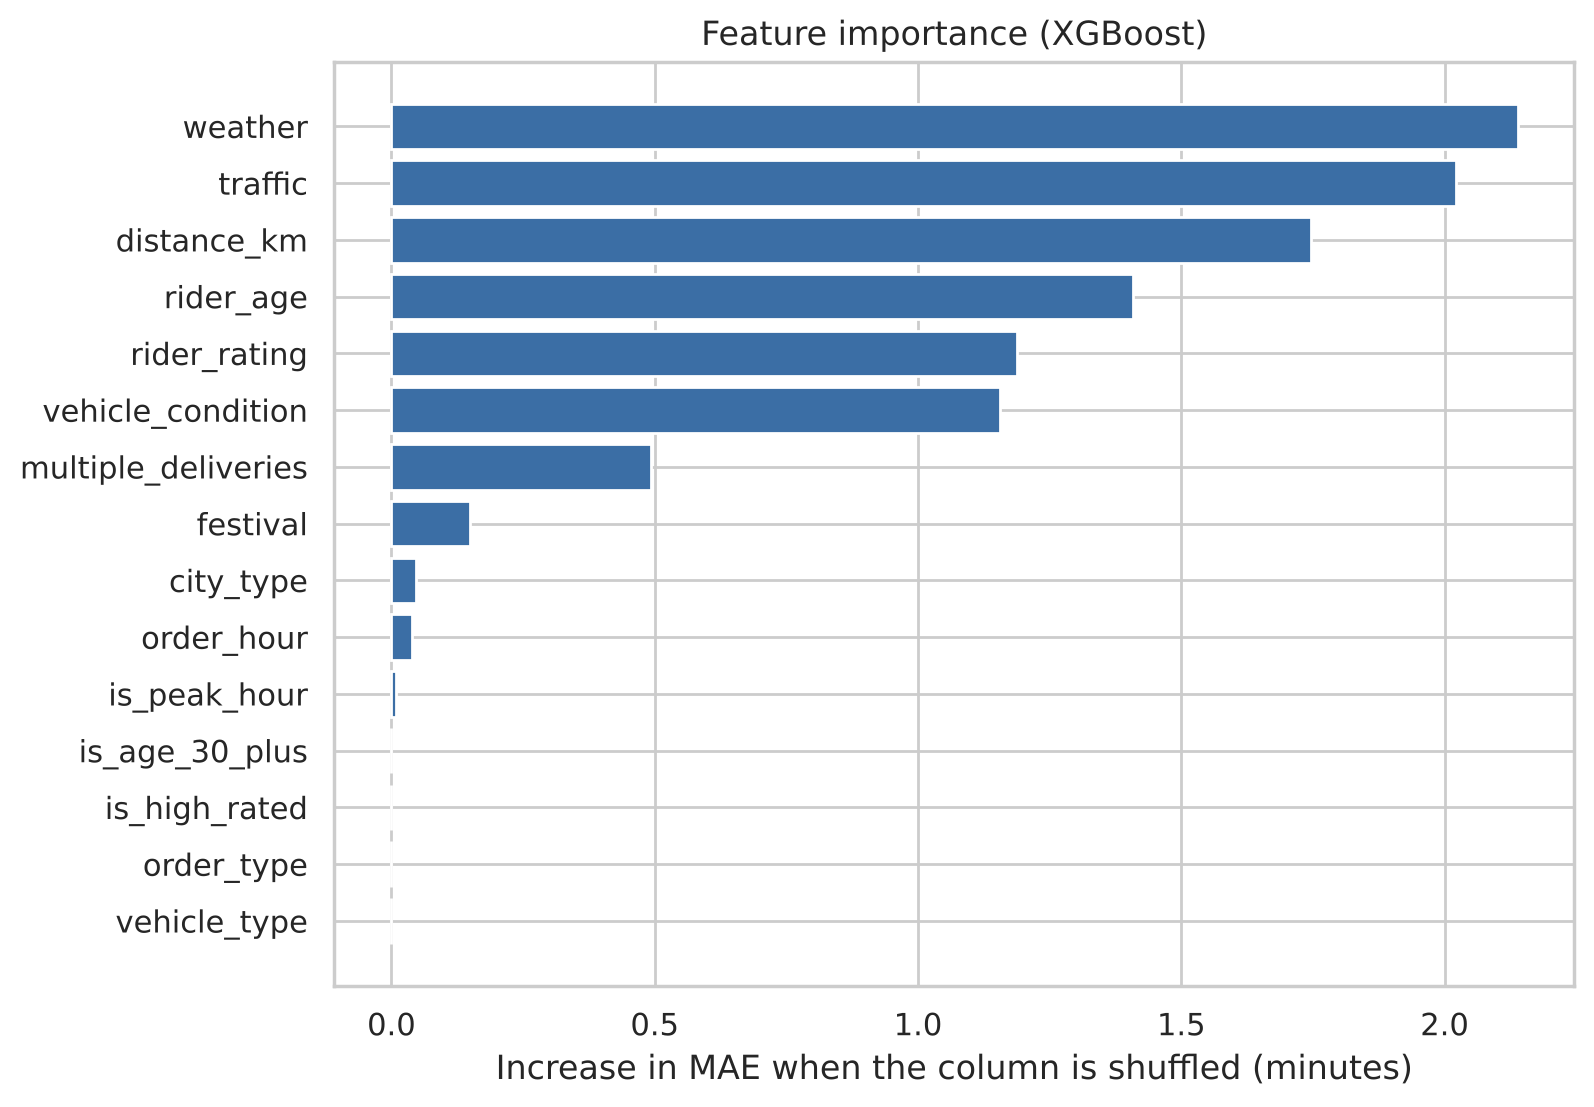

weather                2.139
traffic                2.022
distance_km            1.746
rider_age              1.409
rider_rating           1.187
vehicle_condition      1.156
multiple_deliveries    0.493
festival               0.150
city_type              0.047
order_hour             0.040
is_peak_hour           0.008
is_age_30_plus         0.000
is_high_rated          0.000
order_type            -0.000
vehicle_type          -0.001
dtype: float64

In [20]:
start = time.time()
importance = permutation_importance(best_pipeline, X_test, y_test, n_repeats=5,
                                    random_state=SEED, scoring="neg_mean_absolute_error")

# importances_mean = average increase in MAE (minutes) when that column is shuffled
importance_table = pd.Series(importance.importances_mean, index=X_test.columns).sort_values()
print(f"Done in {time.time() - start:.0f} s")

plt.figure(figsize=(8, 6))
plt.barh(importance_table.index, importance_table.values, color=COLOR)
plt.xlabel("Increase in MAE when the column is shuffled (minutes)")
plt.title(f"Feature importance ({BEST_MODEL_NAME})")
plt.show()

importance_table.sort_values(ascending=False).round(3)

**What we see:**
- The top drivers are **weather** (+2.1 min of error when shuffled), **traffic** (+2.0) and **distance** (+1.7), then rider age, rider rating and vehicle condition (each above +1 min), then multiple deliveries.
- **Order type and vehicle type are close to 0.** This confirms the EDA: package type does not change delivery time.
- The two step flags (is_high_rated, is_age_30_plus) score 0 here, because XGBoost already finds those steps from the raw age and rating columns. The flags still help Linear Regression (step 6), which needs them.

## Step 12: Save the model and the report

- `model.pkl`: the full best pipeline (preprocessing + model), trained on the training set. The app loads this one file and never needs to scale or encode anything by hand.
- `model_report.json`: scores, the prediction range, feature lists and the input choices the app needs for its form.

In [21]:
os.makedirs("models", exist_ok=True)

# 1. the trained pipeline
joblib.dump(best_pipeline, "models/model.pkl")

# 2. the report (only plain numbers and text, so json can save it)
sample = pd.DataFrame({"actual": y_test, "predicted": best_prediction}).sample(1500, random_state=SEED)

report = {
    "best_model": BEST_MODEL_NAME,
    "test_metrics": {
        "MAE": float(test_table.loc[BEST_MODEL_NAME, "MAE"]),
        "RMSE": float(test_table.loc[BEST_MODEL_NAME, "RMSE"]),
        "R2": float(test_table.loc[BEST_MODEL_NAME, "R2"]),
        "within_5_min_percent": float((errors.abs() <= 5).mean() * 100),
    },
    "prediction_range": {"low": float(RANGE_LOW), "high": float(RANGE_HIGH), "coverage_percent": float(inside.mean() * 100)},
    "model_comparison_test": test_table.reset_index().to_dict(orient="records"),
    "model_comparison_cv": final_cv_table.reset_index().rename(columns={"index": "model"}).to_dict(orient="records"),
    "feature_importance": importance_table.sort_values(ascending=False).round(4).to_dict(),
    "error_by_traffic": traffic_error.round(3).to_dict(),
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "category_options": {col: sorted(X_train[col].dropna().unique().tolist()) for col in CATEGORICAL_FEATURES},
    "actual_vs_predicted_sample": sample.round(2).values.tolist(),
}

with open("models/model_report.json", "w") as file:
    json.dump(report, file, indent=2)

print("Saved models/model.pkl and models/model_report.json")

Saved models/model.pkl and models/model_report.json


## Step 13: Use the saved model on a brand-new order

This is exactly what the Streamlit app will do: take raw order details, build the same features as notebook 2, load `model.pkl`, and predict with a range.

In [22]:
def haversine_km(lat1, lon1, lat2, lon2):
    # same formula as notebook 2: straight-line distance on the Earth's surface
    R = 6371
    lat1, lon1, lat2, lon2 = np.radians(lat1), np.radians(lon1), np.radians(lat2), np.radians(lon2)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


def make_features(order):
    # turn raw order details (a dictionary) into the 15 model features (a one-row table)
    row = {
        "distance_km": haversine_km(order["restaurant_lat"], order["restaurant_lon"],
                                    order["delivery_lat"], order["delivery_lon"]),
        "multiple_deliveries": order["multiple_deliveries"],
        "rider_rating": order["rider_rating"],
        "is_high_rated": 1.0 if order["rider_rating"] >= 4.5 else 0.0,
        "rider_age": order["rider_age"],
        "is_age_30_plus": 1.0 if order["rider_age"] >= 30 else 0.0,
        "vehicle_condition": order["vehicle_condition"],
        "order_hour": order["order_hour"],
        "is_peak_hour": 1.0 if 19 <= order["order_hour"] <= 21 else 0.0,
        "weather": order["weather"],
        "traffic": order["traffic"],
        "city_type": order["city_type"],
        "festival": order["festival"],
        "vehicle_type": order["vehicle_type"],
        "order_type": order["order_type"],
    }
    return pd.DataFrame([row])

In [23]:
# load the saved model from disk (as the app will)
loaded_model = joblib.load("models/model.pkl")

new_order = {
    "restaurant_lat": 12.914264, "restaurant_lon": 77.678400,   # restaurant in Bangalore
    "delivery_lat": 12.954264, "delivery_lon": 77.718400,       # customer about 6 km away
    "multiple_deliveries": 1, "rider_rating": 4.6, "rider_age": 32, "vehicle_condition": 1,
    "order_hour": 20, "weather": "Fog", "traffic": "Jam", "city_type": "Metropolitan",
    "festival": "No", "vehicle_type": "motorcycle", "order_type": "Meal",
}

features = make_features(new_order)
eta = loaded_model.predict(features)[0]

print(f"Distance: {features['distance_km'][0]:.1f} km")
print(f"Predicted delivery time: {eta:.0f} min")
print(f"Likely range: {eta + RANGE_LOW:.0f} to {eta + RANGE_HIGH:.0f} min")

Distance: 6.2 km
Predicted delivery time: 31 min
Likely range: 26 to 36 min


In [24]:
# What-if: same order, but change one thing at a time
what_if = {
    "As ordered (Fog, Jam)": new_order,
    "Sunny instead of Fog": {**new_order, "weather": "Sunny"},
    "Low traffic instead of Jam": {**new_order, "traffic": "Low"},
    "Festival day": {**new_order, "festival": "Yes"},
    "Rider carries 2 extra orders": {**new_order, "multiple_deliveries": 2},
}

for label, order in what_if.items():
    print(f"{label:30s} -> {loaded_model.predict(make_features(order))[0]:.1f} min")

As ordered (Fog, Jam)          -> 30.9 min
Sunny instead of Fog           -> 20.2 min


Low traffic instead of Jam     -> 18.0 min
Festival day                   -> 39.7 min
Rider carries 2 extra orders   -> 37.1 min


## Summary

| Item | Result |
|---|---|
| Models compared | Linear Regression, Random Forest, XGBoost, ANN (MLP) |
| Validation | 5-fold cross validation on the training set, one final test on a hidden 20% |
| Tuning | RandomizedSearchCV (helped XGBoost and Random Forest; ANN kept at default) |
| **Best model** | **XGBoost** |
| Test MAE / RMSE / R² | **3.07 min / 3.86 min / 0.83** |
| vs naive baseline | Error cut from 7.66 to 3.07 min (60% lower) |
| Within 5 minutes | 81.6% of orders |
| Prediction range | About -4.7 to +5.0 min around the prediction, holds for 80% of orders |
| Top drivers | Weather, traffic, distance, rider age and rating, vehicle condition |
| Feature engineering gain | XGBoost error 3.95 -> 3.15 min in cross validation |

<br>

## Problem statement challenges and how we handled them

| Challenge | What we did |
|---|---|
| Missing or inconsistent data | Cleaned in notebook 1; missing values filled inside the pipeline (median / most frequent) |
| Overfitting | 5-fold cross validation, a hidden test set, early stopping for the ANN; test scores match CV scores |
| Highly correlated features | Checked in notebook 2: no harmful pairs, so no PCA needed |
| Slow training | XGBoost with all CPU cores, RandomizedSearchCV instead of a full grid |

<br>

## Next: the Streamlit app

The app loads `models/model.pkl` and `models/model_report.json`, uses the same `make_features` function, and shows the ETA with its range, what-if comparisons, and a model insights page.